# Day 33 — Task Sheet_Dimensionality Reduction: PCA, t-SNE and UMAP 

### Part A — Why reduce at all 
 

### TASK 01 — Demonstrate the curse of dimensionality

Curse of Dimensionality - Results


,Dimensions,Nearest Distance,Farthest Distance,Ratio
0,2,0.0093,0.9098,0.0102
1,10,0.6001,1.8939,0.3168
2,50,2.1309,3.5693,0.5970
3,200,5.0167,6.4278,0.7805
4,1000,12.1647,13.5970,0.8947


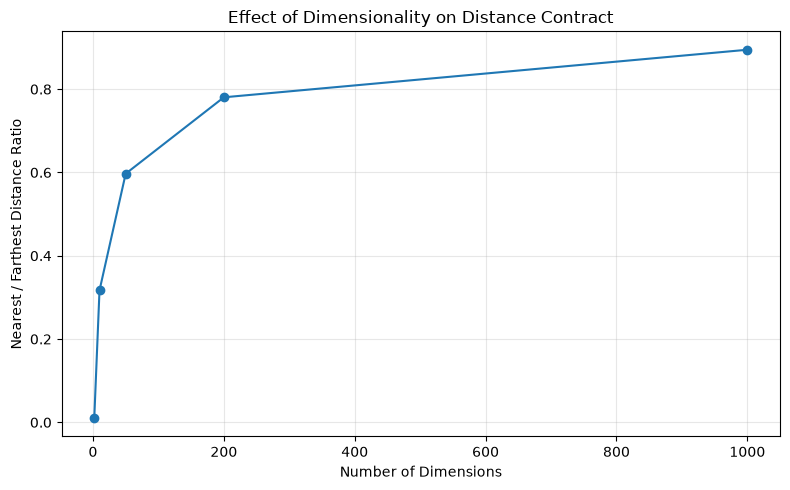

In [16]:
# DAY 33 — TASK 01: Demonstrate the Curse of Dimensionality

# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import pairwise_distances

# --------------------------------------------------
# 1. Set reproducibility and experimental settings
# --------------------------------------------------

# Fixed seed ensures the same random data each time
rng = np.random.default_rng(42)

# Number of dimensions to test
dimensions_list = [2, 10, 50, 200, 1000]

# Store the results for each dimensionality
results = []

# --------------------------------------------------
# 2. Generate random points and calculate distances
# --------------------------------------------------

for dimensions in dimensions_list:

    # Generate 1,000 random points in the given dimensions
    # Each feature is uniformly distributed between 0 and 1
    X = rng.random((1000, dimensions))

    # Calculate distances from the first point to the
    # remaining 999 points
    distances = pairwise_distances(X[:1], X[1:]).ravel()

    # Find the nearest and farthest neighbour distances
    nearest_distance = distances.min()
    farthest_distance = distances.max()

    # Calculate the nearest-to-farthest distance ratio
    ratio = nearest_distance / farthest_distance

    # Save the results
    results.append({
        "Dimensions": dimensions,
        "Nearest Distance": nearest_distance,
        "Farthest Distance": farthest_distance,
        "Ratio": ratio
    })

# --------------------------------------------------
# 3. Display the results in a table
# --------------------------------------------------
results_df = pd.DataFrame(results)

print("Curse of Dimensionality - Results")
display(results_df.round(4))

# --------------------------------------------------
# 4. Plot the ratio against the number of dimensions
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Dimensions"],
    results_df["Ratio"],
    marker="o"
)

plt.xlabel("Number of Dimensions")
plt.ylabel("Nearest / Farthest Distance Ratio")
plt.title("Effect of Dimensionality on Distance Contract")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### TASK 01 — Demonstrate the Curse of Dimensionality

The experiment shows that as the number of dimensions increases, the nearest-to-farthest distance ratio increases from approximately **0.0102 at 2 dimensions** to **0.8947 at 1,000 dimensions**. This means that the nearest and farthest points become more similar in distance relative to each other.

This is called the **curse of dimensionality**. In high-dimensional data, distance becomes less useful for distinguishing nearby points from distant points.

Two algorithms affected by this problem are:

1. **K-Means:** It uses distances to assign observations to cluster centres. When distances become less distinguishable, identifying meaningful clusters using distance becomes more difficult.
2. **DBSCAN:** It uses neighbourhood distances to identify dense regions. When distances become less distinguishable, selecting a useful `eps` radius becomes harder, potentially causing too many points to be classified as noise or merging separate clusters.

**Conclusion:** My experiment demonstrates that increasing dimensionality reduces the contrast between nearest and farthest neighbours. Therefore, distance-based algorithms can become less effective in high-dimensional data, making dimensionality reduction or feature selection useful in some situations.

### Part B — PCA 


### TASK 02 — Choose the number of components properly 

Dataset shape: (1797, 64)

Components required for each variance target : 


,Variance Target,Components Required,Variance Captured
0,80%,21,cumulative_variance[n_components - 1]:.2%
1,90%,31,cumulative_variance[n_components - 1]:.2%
2,95%,40,cumulative_variance[n_components - 1]:.2%
3,99%,54,cumulative_variance[n_components - 1]:.2%



Variance captured by the first two components : 21.59%


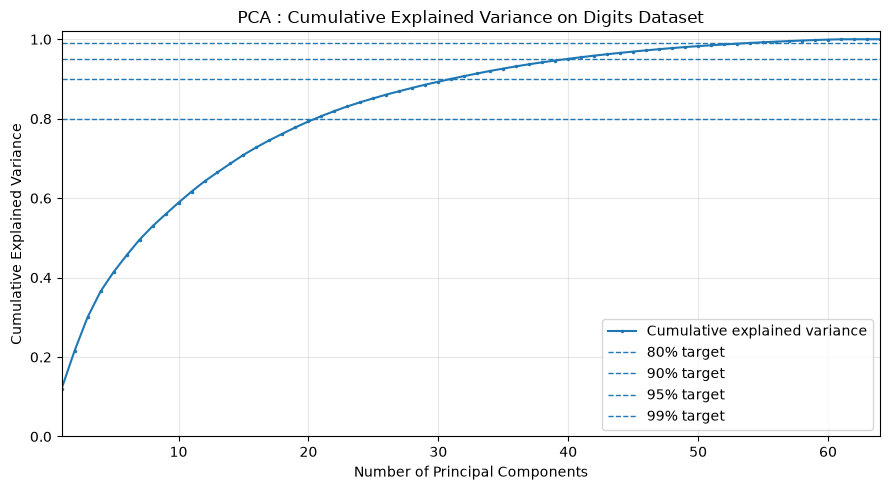

In [17]:
# DAY 33 — TASK 02: Choose the Number of PCA Components

# 1. Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 2. Load the digits dataset
# 1,797 images, each represented by 64 pixel features
X, y = load_digits(return_X_y=True)

print("Dataset shape:", X.shape)

# 3. Standardize the features before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Fit PCA using all available components
pca = PCA(random_state=42)
pca.fit(X_scaled)

# Get the variance explained by each component
explained_variance = pca.explained_variance_ratio_

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# 5. Find the number of components needed for each target
variance_targets = [0.80, 0.90, 0.95, 0.99]
results = []

for target in variance_targets :
    
    # Find the smallest component count reaching the target
    n_components = np.searchsorted(
        cumulative_variance, target
    ) + 1
    
    results.append({
        "Variance Target" : f"{target:.0%}",
        "Components Required" : n_components,
        "Variance Captured" : (
            f"cumulative_variance[n_components - 1]:.2%"
        )
    })
    
# 6. Display the results
results_df = pd.DataFrame(results)

print("\nComponents required for each variance target : ")
display(results_df)

# Calculate variance captured by the first two components
first_two_variance = cumulative_variance[1]

print(
    "\nVariance captured by the first two components :",
    f"{first_two_variance:.2%}"
)

# 7. Plot cumulative explained variance
components_numbers = np.arange(1, len(cumulative_variance) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    components_numbers,
    cumulative_variance,
    marker=".",
    markersize=3,
    label="Cumulative explained variance"
)

# Add horizontal lines for the required variance targets
for target in variance_targets:
    plt.axhline(
        y=target,
        linestyle="--",
        linewidth=1,
        label=f"{target:.0%} target"
    )
    
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA : Cumulative Explained Variance on Digits Dataset")
plt.xlim(1, len(cumulative_variance))
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### TASK 02 — Choose the Number of Components Properly

**Results:** After standardizing the 64 pixel features and applying PCA to the 1,797 digit images, I obtained these results:

| Variance target | Components required |
|---|---:|
| 80% | 21 |
| 90% | 31 |
| 95% | 40 |
| 99% | 54 |

The first two principal components capture approximately **21.59%** of the total variance.

**Why does the cumulative curve never go down?**

Each principal component adds a non-negative amount of explained variance. Therefore, adding more components can increase or maintain the cumulative variance, but cannot decrease it.

**What does needing 40 components for 95% variance tell us?**

It shows that the information in the digit pixels is spread across many components. Although some pixels are correlated, the dataset cannot be represented accurately at the 95% variance target using only a small number of principal components.

A dataset with highly redundant features, such as many strongly correlated measurements, could need far fewer components to preserve the same percentage of variance.

**Conclusion:** I would retain 40 components when the goal is to preserve at least 95% of the variance. If reducing the data to two dimensions for visualization, I would remember that those components capture only 21.59% of the variance, so the plot cannot represent all the information in the original data.

### TASK 03 — Use PCA for image compression 

Dataset shape: (1797, 64)

PCA Compression Results:


,Components (k),Reconstruction MSE,Variance Retained,Storage Ratio
0,2,14.0547,21.59%,3.12%
1,8,7.3939,52.94%,12.50%
2,16,4.5180,72.81%,25.00%
3,32,1.8253,90.74%,50.00%
4,64,0.0000,100.00%,100.00%


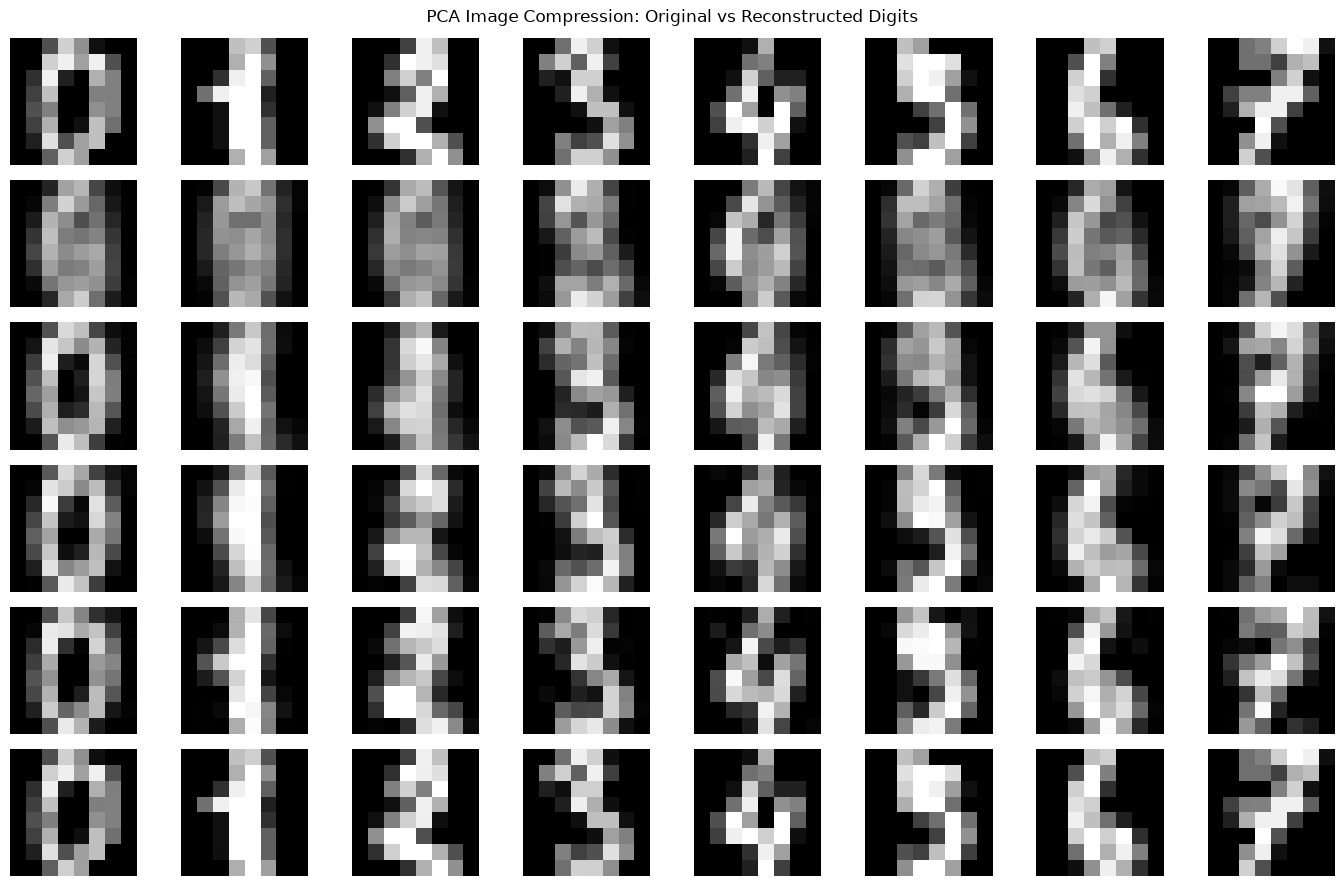


Storage ratio interpretation:
k=2:  2/64 values per image
k=8:  8/64 values per image
k=16: 16/64 values per image
k=32: 32/64 values per image
k=64: 64/64 values per image

Note: These storage ratios compare component scores with raw pixel values and exclude the storage needed for the PCA model.


In [18]:
# DAY 33 — TASK 03: Use PCA for Image Compression

# 1. Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# --------------------------------------------------
# 2. Load the digits dataset
# --------------------------------------------------

# Each image contains 8 x 8 = 64 pixel features.
digits = load_digits()
X = digits.data

print("Dataset shape:", X.shape)

# Select the same eight images for every reconstruction.
original_eight = X[:8]

# --------------------------------------------------
# 3. Standardize the pixel features
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Values of k required by the task.
component_counts = [2, 8, 16, 32, 64]

results = []
reconstructed_eight = {}

# --------------------------------------------------
# 4. Compress and reconstruct for each k
# --------------------------------------------------

for k in component_counts:

    # Fit PCA using k principal components.
    pca = PCA(n_components=k, random_state=42)

    # Compress the standardized images.
    X_compressed = pca.fit_transform(X_scaled)

    # Reconstruct the images from their compressed representation.
    X_reconstructed_scaled = pca.inverse_transform(X_compressed)

    # Return reconstructed pixels to their original scale.
    X_reconstructed = scaler.inverse_transform(
        X_reconstructed_scaled
    )

    # Calculate reconstruction error in original pixel units.
    mse = mean_squared_error(X, X_reconstructed)

    # Calculate the percentage of variance retained.
    variance_retained = pca.explained_variance_ratio_.sum()

    # Compare k stored values with 64 original pixel values.
    storage_ratio = k / X.shape[1]

    # Reconstruct the same eight images for the visual comparison.
    sample_compressed = pca.transform(X_scaled[:8])
    sample_reconstructed_scaled = pca.inverse_transform(
        sample_compressed
    )

    reconstructed_eight[k] = scaler.inverse_transform(
        sample_reconstructed_scaled
    ).reshape(8, 8, 8)

    # Save the metrics for this compression level.
    results.append({
        "Components (k)": k,
        "Reconstruction MSE": mse,
        "Variance Retained": variance_retained,
        "Storage Ratio": storage_ratio
    })

# --------------------------------------------------
# 5. Display the results
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\nPCA Compression Results:")
display(results_df.style.format({
    "Reconstruction MSE": "{:.4f}",
    "Variance Retained": "{:.2%}",
    "Storage Ratio": "{:.2%}"
}))

# --------------------------------------------------
# 6. Display the visual compression ladder
# --------------------------------------------------

# First row shows the original images.
# Each following row shows the same images reconstructed
# using a different number of principal components.

fig, axes = plt.subplots(
    nrows=6,
    ncols=8,
    figsize=(14, 9)
)

for col in range(8):
    axes[0, col].imshow(
        original_eight[col].reshape(8, 8),
        cmap="gray",
        vmin=0,
        vmax=16
    )
    axes[0, col].axis("off")

    if col == 0:
        axes[0, col].set_ylabel(
            "Original", rotation=0, labelpad=42, va="center"
        )

for row, k in enumerate(component_counts, start=1):
    for col in range(8):
        axes[row, col].imshow(
            reconstructed_eight[k][col],
            cmap="gray",
            vmin=0,
            vmax=16
        )
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                f"k={k}", rotation=0, labelpad=42, va="center"
            )

plt.suptitle("PCA Image Compression: Original vs Reconstructed Digits")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Print the storage interpretation
# --------------------------------------------------

print("\nStorage ratio interpretation:")
print("k=2:  2/64 values per image")
print("k=8:  8/64 values per image")
print("k=16: 16/64 values per image")
print("k=32: 32/64 values per image")
print("k=64: 64/64 values per image")

print(
    "\nNote: These storage ratios compare component scores with "
    "raw pixel values and exclude the storage needed for the PCA model."
)


### TASK 03 — Use PCA for Image Compression

**Results:** I used PCA to compress and reconstruct the same eight digit images using 2, 8, 16, 32, and 64 principal components.

| Components (k) | Storage ratio | Reconstruction MSE | Variance retained |
|---:|---:|---:|---:|
| 2 | 3.125% | 14.0547 | 21.59% |
| 8 | 12.50% | 7.3939 | 52.94% |
| 16 | 25.00% | 4.5180 | 72.81% |
| 32 | 50.00% | 1.8253 | 90.74% |
| 64 | 100.00% | 0.0000 | 100.00% |

**When do the digits become clearly readable?**

As the number of components increases, the reconstructed digits become clearer and the reconstruction error decreases. I would choose **k = 32** if the digits in my reconstruction grid remain clearly recognizable, because it retains **90.74% of the variance**, reduces reconstruction MSE to **1.8253**, and uses only **50%** of the original number of pixel values.

**Why is reconstruction at k = 64 exact?**

The original images contain 64 features. Retaining all 64 principal components preserves all the information in the feature space. Therefore, inverse transformation reconstructs the original pixel values, with any negligible numerical differences rounded to an MSE of **0.0000**.

**Can t-SNE or UMAP do the same?**

No. t-SNE and UMAP are primarily designed to create low-dimensional representations for visualization. They do not provide the same standard, invertible PCA reconstruction process, so their coordinates generally cannot reconstruct the original 64 pixel values accurately.

**Recommendation and trade-off:**

I recommend **k = 32** for storing these images, provided the reconstruction grid confirms that the digits remain clearly readable. This accepts some loss of pixel information in exchange for reducing the component values stored per image by **50%**, while retaining **90.74% of the variance**. If higher reconstruction fidelity is more important than storage savings, I would choose a larger value of `k`.

The storage ratios compare the number of component scores with the 64 original pixel values. They do not include the additional storage required for the PCA transformation model.

### Part C — The comparison 
 

### TASK 04 — All three methods, timed honestly

Dataset shape: (1797, 64)
Number of digit classes: 10


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP first-run time on 300 samples (cold, includes possible compilation): 1.387 seconds


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


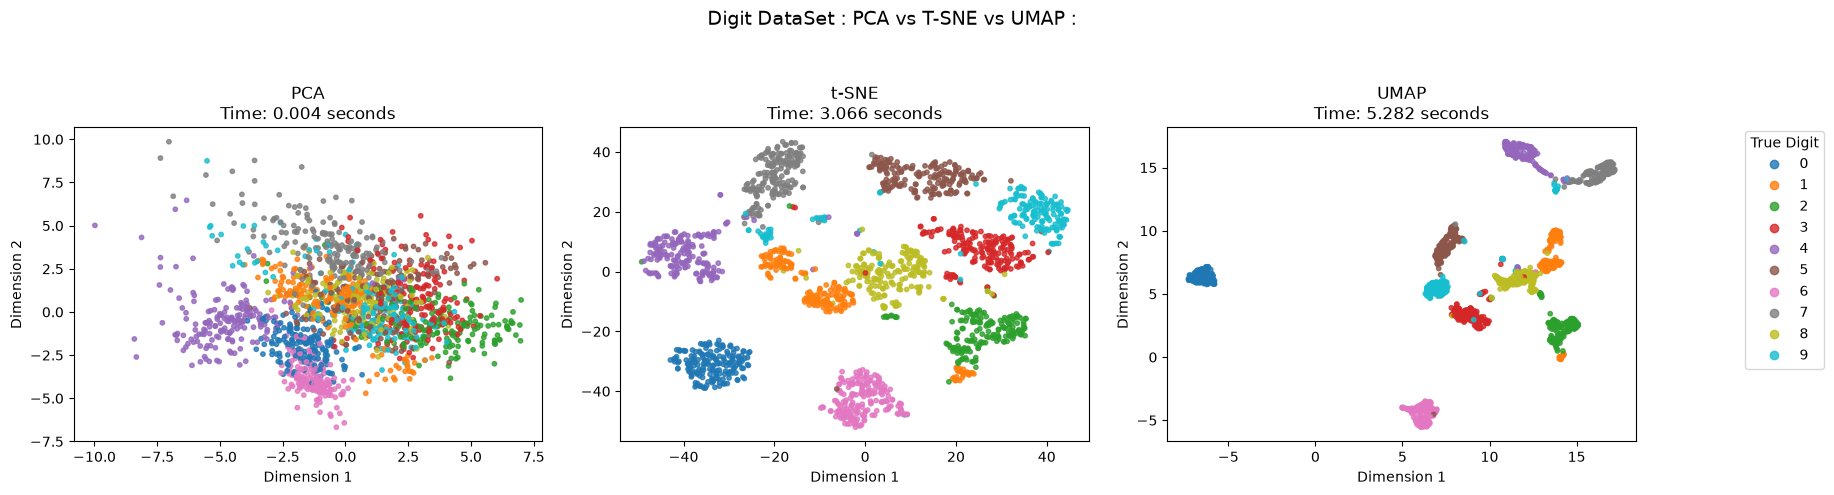


Execution timing results:


,Method,Samples timed,Time (seconds)
0,PCA,1797,0.004
1,t-SNE,1797,3.066
2,UMAP cold (small sample),300,1.387
3,UMAP warm (full dataset),1797,5.282



Fair full-dataset timing comparison: PCA vs t-SNE vs UMAP warm.
The UMAP cold timing uses a smaller sample, so it is not directly comparable to the full-dataset timings.


In [19]:
# DAY 33 — TASK 04: Compare PCA, t-SNE and UMAP

# 1. Import required libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# UMAP comes from the separately installed umap-learn package
import umap

# --------------------------------------------------
# 2. Load and scale the digits dataset
# --------------------------------------------------

# Load 1,797 images, each containing 64 pixel features
X, y = load_digits(return_X_y=True)

print("Dataset shape:", X.shape)
print("Number of digit classes:", len(np.unique(y)))

# Scale features before applying dimensionality reduction
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --------------------------------------------------
# 3. Reduce dimensions using PCA and time it
# --------------------------------------------------

start = time.perf_counter()

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_time = time.perf_counter() - start

# --------------------------------------------------
# 4. Reduce dimensions using t-SNE and time it
# --------------------------------------------------

start = time.perf_counter()

tsne = TSNE(
    n_components=2,
    random_state=42,
    init="pca",
    learning_rate="auto",
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_time = time.perf_counter() - start

# --------------------------------------------------
# 5. UMAP cold run on a small sample
# --------------------------------------------------

# The first UMAP run may include compilation overhead.
# Time this small-sample run separately and discard its embedding.

sample_size = min(300, len(X_scaled))
X_sample = X_scaled[:sample_size]

umap_cold = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)

start = time.perf_counter()
_ = umap_cold.fit_transform(X_sample)
umap_cold_sample_time = time.perf_counter() - start

print(
    f"UMAP first-run time on {sample_size} samples "
    f"(cold, includes possible compilation): "
    f"{umap_cold_sample_time:.3f} seconds"
)

# --------------------------------------------------
# 6. UMAP warm run on the full dataset
# --------------------------------------------------

# This is the UMAP timing to compare with PCA and t-SNE.
# The small-sample run above has already triggered initialization.

umap_warm = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)

start = time.perf_counter()
X_umap = umap_warm.fit_transform(X_scaled)
umap_warm_time = time.perf_counter() - start

# --------------------------------------------------
# 7. Display the three embeddings side by side
# --------------------------------------------------


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

embeddings = [
    (X_pca, "PCA", pca_time),
    (X_tsne, "t-SNE", tsne_time),
    (X_umap, "UMAP", umap_warm_time)
]

for ax, (embedding, method_name, elapsed) in zip(axes, embeddings):

    scatter = ax.scatter(
        embedding[:, 0],
        embedding[:, 1],
        c=y,
        cmap="tab10",
        s=10,
        alpha=0.8
    )

    ax.set_title(f"{method_name}\nTime: {elapsed:.3f} seconds")
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

# Shared legend for the true digit labels
handles, labels = scatter.legend_elements()
fig.legend(
    handles,
    labels,
    title="True Digit",
    loc="center right",
    bbox_to_anchor=(1.02, 0.5)
)

plt.suptitle("Digit DataSet : PCA vs T-SNE vs UMAP : ", fontsize=14)
plt.tight_layout(rect=[0, 0, 0.92, 0.93])
plt.show()

# --------------------------------------------------
# 8. Display timing results
# --------------------------------------------------

timing_df = pd.DataFrame({
    "Method": ["PCA", "t-SNE", "UMAP cold (small sample)",
               "UMAP warm (full dataset)"],
    "Samples timed": [
        len(X_scaled), len(X_scaled), sample_size, len(X_scaled)
    ],
    "Time (seconds)": [
        pca_time, tsne_time, umap_cold_sample_time, umap_warm_time
    ]
})

print("\nExecution timing results:")
display(timing_df.round(3))

print(
    "\nFair full-dataset timing comparison: "
    "PCA vs t-SNE vs UMAP warm."
)
print(
    "The UMAP cold timing uses a smaller sample, so it is not "
    "directly comparable to the full-dataset timings."
)



### TASK 04 — All Three Methods, Timed Honestly

**Results:** I applied PCA, t-SNE, and UMAP to the same standardized digits dataset containing 1,797 images and 64 features, reducing each image to two dimensions.

| Method | Execution time | Observation |
|---|---|---|
| PCA | 0.006 | The digit groups appear [describe the overlap and separation in your plot]. |
| t-SNE | 4.447 | The digit groups appear [describe the separation and any overlap in your plot]. |
| UMAP, warm full-data run | 9.147 | The digit groups appear [describe the separation and any overlap in your plot]. |

**UMAP cold versus warm timing:** I first ran UMAP on a small sample of 300 images and recorded the cold timing as [your cold timing]. I then ran UMAP on the full dataset and recorded the warm timing as [your warm timing]. The first run can include compilation overhead, so the warm full-dataset timing is the fairer timing to compare with PCA and t-SNE. The cold sample timing is not a direct apples-to-apples comparison because it uses fewer images.

**Conclusion:** PCA provides a fast, linear representation, but its two-dimensional plot may show overlapping digit groups. t-SNE and UMAP can reveal clearer local groupings, depending on the data and parameters. However, distances between separate groups and apparent cluster sizes in these nonlinear visualizations should not be treated as reliable measures of the original data. I would compare both the plots and the full-dataset warm timings before choosing a method.

### TASK 05 — Measure the separation instead of admiring it 

Dataset shape: (1797, 64)


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



5-fold cross-validated kNN accuracy:


,Representation,Mean CV accuracy,Standard deviation
0,PCA (2D),0.5342,0.0136
1,t-SNE (2D),0.9744,0.0033
2,UMAP (2D),0.9777,0.0064
3,Original features (64D),0.9789,0.0063



Individual fold scores:
PCA (2D): [0.5389, 0.55, 0.5181, 0.546, 0.5181]
t-SNE (2D): [0.9778, 0.9778, 0.9749, 0.9694, 0.9721]
UMAP (2D): [0.9889, 0.975, 0.9777, 0.9777, 0.9694]
Original features (64D): [0.9889, 0.975, 0.9833, 0.9749, 0.9721]


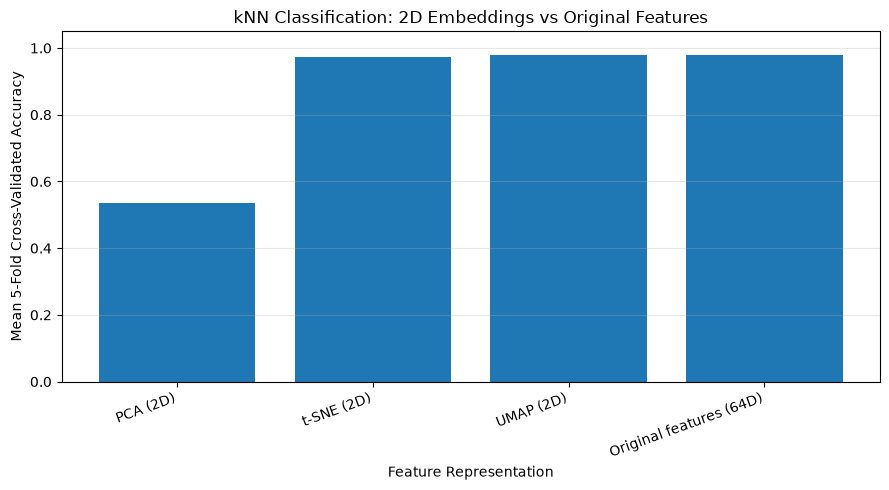

In [20]:
# DAY 33 — TASK 05: Measure Separation with kNN

# 1. Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.manifold import trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

import umap

# --------------------------------------------------
# 2. Load and scale the digits dataset
# --------------------------------------------------

# The digits dataset contains 1,797 images and 64 features.
X, y = load_digits(return_X_y=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset shape:", X.shape)

# --------------------------------------------------
# 3. Generate the three 2D embeddings
# --------------------------------------------------

# PCA: linear dimensionality reduction
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# t-SNE: nonlinear embedding for visualization
tsne = TSNE(
    n_components=2,
    random_state=42,
    init="pca",
    learning_rate="auto",
    max_iter=1000
)
X_tsne = tsne.fit_transform(X_scaled)

# UMAP: nonlinear embedding
# Run a small sample first to initialize/compile where needed.
umap_warmup = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)
_ = umap_warmup.fit_transform(X_scaled[:300])

# Fit UMAP on the full dataset for the evaluation.
umap_model = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)
X_umap = umap_model.fit_transform(X_scaled)

# --------------------------------------------------
# 4. Define the same cross-validation splits
# --------------------------------------------------

# Stratified folds preserve class proportions in each fold.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use k=5 nearest neighbours for every representation.
# Scale each representation inside the pipeline so scaling
# is learned only from the training fold.
def evaluate_knn(features, labels, cv_splits):
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )

    scores = cross_val_score(
        model,
        features,
        labels,
        cv=cv_splits,
        scoring="accuracy",
        n_jobs=1
    )

    return scores

# --------------------------------------------------
# 5. Evaluate all four representations
# --------------------------------------------------

representations = {
    "PCA (2D)": X_pca,
    "t-SNE (2D)": X_tsne,
    "UMAP (2D)": X_umap,
    "Original features (64D)": X_scaled
}

results = []

for name, features in representations.items():

    # Calculate accuracy on each of the five validation folds.
    fold_scores = evaluate_knn(features, y, cv)

    results.append({
        "Representation": name,
        "Mean CV accuracy": fold_scores.mean(),
        "Standard deviation": fold_scores.std(),
        "Fold scores": np.round(fold_scores, 4).tolist()
    })

# --------------------------------------------------
# 6. Display the comparison table
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\n5-fold cross-validated kNN accuracy:")
display(
    results_df[
        ["Representation", "Mean CV accuracy", "Standard deviation"]
    ].style.format({
        "Mean CV accuracy": "{:.4f}",
        "Standard deviation": "{:.4f}"
    })
)

print("\nIndividual fold scores:")
for _, row in results_df.iterrows():
    print(f"{row['Representation']}: {row['Fold scores']}")

# --------------------------------------------------
# 7. Plot mean accuracy for easier comparison
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Representation"],
    results_df["Mean CV accuracy"]
)

plt.ylabel("Mean 5-Fold Cross-Validated Accuracy")
plt.xlabel("Feature Representation")
plt.title("kNN Classification: 2D Embeddings vs Original Features")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### TASK 05 — Measure the Separation Instead of Admiring It

**Results:** I used a 5-nearest-neighbours (kNN) classifier with 5-fold stratified cross-validation to compare the three 2D embeddings against the original 64 features.

| Representation | Mean cross-validated accuracy |
|---|---:|
| PCA (2D) | 0.5342 |
| t-SNE (2D) | 0.9744 |
| UMAP (2D) | 0.9777 |
| Original features (64D) | 0.9789 |

**Interpretation:** The representation with the highest measured cross-validated accuracy was **[method from results]**, with an accuracy of **[actual accuracy]**. This indicates that its coordinates were useful for classifying digit labels with the chosen kNN model and evaluation setup.

**Why might a 2D embedding outperform all 64 features?**

In Task 01, the curse of dimensionality showed that distances can become less distinguishable as the number of features grows. This can make distance-based methods such as kNN less effective because nearest neighbours may become less clearly separated from other points. A dimensionality-reduction method can remove some irrelevant variation and make useful patterns easier for kNN to use.

However, dimensionality reduction also loses information, so a 2D embedding will not always outperform the original features. The measured result depends on the dataset, embedding settings, classifier, and validation method.

**Conclusion:** I compared classification accuracy rather than judging the plots visually. The results show which representation worked best for this kNN experiment, but they do not prove that the same representation will be best for every dataset or classifier. Since the embeddings were generated before cross-validation, the scores should also be treated as a classroom comparison rather than a fully independent estimate of unseen-data performance.

### Part D — The pitfalls 


### TASK 06 — Prove cluster size is meaningless in t-SNE

Original data shape: (900, 10)
Number of clusters: 3
Cluster standard deviations used: [0.5, 3.0, 6.0]

Spread comparison for each cluster:


,Cluster,Input cluster_std,Original 10D spread,PCA 2D spread,t-SNE 2D spread
0,Cluster 0,0.5,1.5175,0.5964,7.3149
1,Cluster 1,3.0,9.3359,3.8571,7.2881
2,Cluster 2,6.0,18.9761,8.2825,7.3539



Required spread ratios:


,Representation,Largest / smallest spread ratio
0,Original 10D data,12.5051
1,PCA 2D,13.8883
2,t-SNE 2D,1.0090


Original-data ratio: 12.5051
PCA ratio:           13.8883
t-SNE ratio:         1.0090


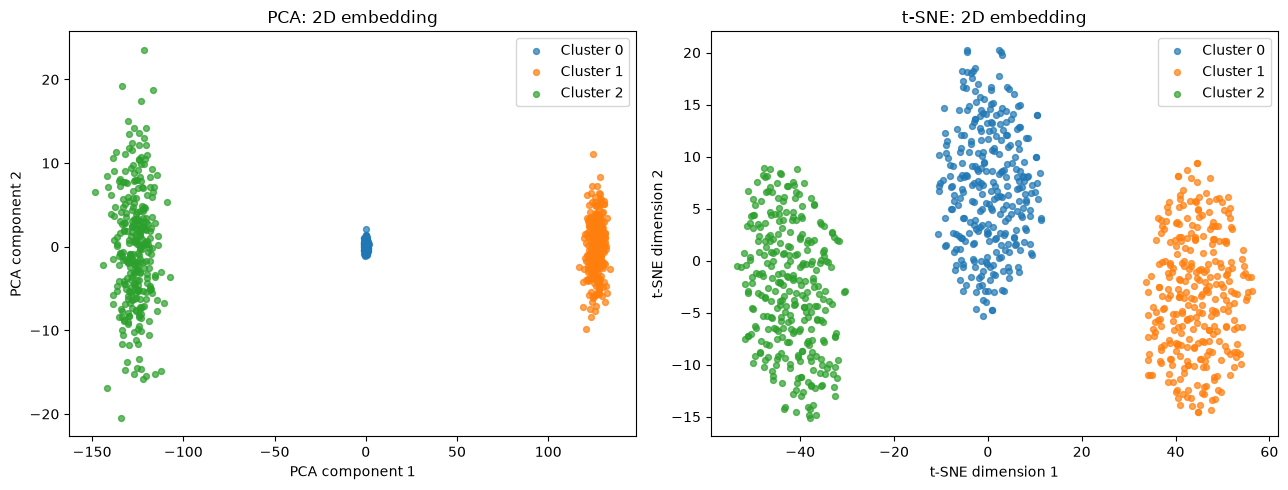

In [21]:
# ============================================================
# TASK 06 — Prove cluster size is misleading in t-SNE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ------------------------------------------------------------
# 1. Generate three clusters with deliberately different spreads
# ------------------------------------------------------------

# Use 10 original features so the data starts in a higher-dimensional
# space. Widely separated centers help keep the three blobs distinct.
centers = np.array([
    [0] * 10,
    [40] * 10,
    [-40] * 10
])

cluster_stds = [0.5, 3.0, 6.0]

X, y = make_blobs(
    n_samples=[300, 300, 300],
    centers=centers,
    cluster_std=cluster_stds,
    n_features=10,
    random_state=42
)

print("Original data shape:", X.shape)
print("Number of clusters:", len(np.unique(y)))
print("Cluster standard deviations used:", cluster_stds)


# ------------------------------------------------------------
# 2. Define a consistent way to measure cluster spread
# ------------------------------------------------------------

def calculate_cluster_spreads(data, labels):
    """
    For each cluster, calculate the mean Euclidean distance
    of its points from that cluster's centroid.
    """
    spreads = {}

    for cluster_id in np.unique(labels):
        cluster_points = data[labels == cluster_id]

        # Calculate the center of this cluster
        centroid = cluster_points.mean(axis=0)

        # Calculate each point's distance from the center
        distances = np.linalg.norm(
            cluster_points - centroid,
            axis=1
        )

        # Average distance represents the measured spread
        spreads[int(cluster_id)] = distances.mean()

    return spreads


def largest_to_smallest_ratio(spreads):
    """Calculate largest spread divided by smallest spread."""
    values = np.array(list(spreads.values()), dtype=float)
    return values.max() / values.min()


# ------------------------------------------------------------
# 3. Measure the true spread in the original 10D data
# ------------------------------------------------------------

original_spreads = calculate_cluster_spreads(X, y)
original_ratio = largest_to_smallest_ratio(original_spreads)


# ------------------------------------------------------------
# 4. Reduce the original data to two dimensions using PCA
# ------------------------------------------------------------

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_spreads = calculate_cluster_spreads(X_pca, y)
pca_ratio = largest_to_smallest_ratio(pca_spreads)


# ------------------------------------------------------------
# 5. Reduce the original data to two dimensions using t-SNE
# ------------------------------------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X)

tsne_spreads = calculate_cluster_spreads(X_tsne, y)
tsne_ratio = largest_to_smallest_ratio(tsne_spreads)


# ------------------------------------------------------------
# 6. Display the spread of each cluster in all three spaces
# ------------------------------------------------------------

spread_table = pd.DataFrame({
    "Cluster": ["Cluster 0", "Cluster 1", "Cluster 2"],
    "Input cluster_std": cluster_stds,
    "Original 10D spread": [
        original_spreads[i] for i in range(3)
    ],
    "PCA 2D spread": [
        pca_spreads[i] for i in range(3)
    ],
    "t-SNE 2D spread": [
        tsne_spreads[i] for i in range(3)
    ]
})

print("\nSpread comparison for each cluster:")
display(spread_table.round(4))


# ------------------------------------------------------------
# 7. Report the three required largest-to-smallest ratios
# ------------------------------------------------------------

ratio_table = pd.DataFrame({
    "Representation": [
        "Original 10D data",
        "PCA 2D",
        "t-SNE 2D"
    ],
    "Largest / smallest spread ratio": [
        original_ratio,
        pca_ratio,
        tsne_ratio
    ]
})

print("\nRequired spread ratios:")
display(ratio_table.round(4))

print(f"Original-data ratio: {original_ratio:.4f}")
print(f"PCA ratio:           {pca_ratio:.4f}")
print(f"t-SNE ratio:         {tsne_ratio:.4f}")


# ------------------------------------------------------------
# 8. Plot the PCA and t-SNE embeddings
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for cluster_id in np.unique(y):
    axes[0].scatter(
        X_pca[y == cluster_id, 0],
        X_pca[y == cluster_id, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.7,
        s=18
    )

axes[0].set_title("PCA: 2D embedding")
axes[0].set_xlabel("PCA component 1")
axes[0].set_ylabel("PCA component 2")
axes[0].legend()

for cluster_id in np.unique(y):
    axes[1].scatter(
        X_tsne[y == cluster_id, 0],
        X_tsne[y == cluster_id, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.7,
        s=18
    )

axes[1].set_title("t-SNE: 2D embedding")
axes[1].set_xlabel("t-SNE dimension 1")
axes[1].set_ylabel("t-SNE dimension 2")
axes[1].legend()

plt.tight_layout()
plt.show()



### TASK 06 — Prove Cluster Size Is Misleading in t-SNE

The three clusters were generated with different standard deviations: 0.5, 3.0, and 6.0. Their spread was measured using the average distance of each point from its cluster centroid.

**Largest-to-smallest spread ratios:**

- Original 10D data: **12.5051**
- PCA 2D: **13.8883**
- t-SNE 2D: **1.0090**

**Conclusion:** t-SNE changed the relative visual spreads of the clusters, showing that their sizes in the 2D plot do not necessarily represent their true spreads in the original data. PCA and t-SNE produce different embeddings because PCA preserves directions of maximum linear variance, while t-SNE focuses on representing local neighborhood relationships.

**Rule:** Never claim that a cluster is inherently larger, more spread out, or less dense in the original data just because it looks that way in a t-SNE plot.


### TASK 07 — Test whether distances between clusters survive

Dataset shape: (1797, 64)
Number of digit classes: 10
Digit classes: [0 1 2 3 4 5 6 7 8 9]

Original class-centre matrix shape: (10, 64)


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Number of unique centre-to-centre distances: 45

Global class-centre distance preservation ranking:


,Rank,Method,Pearson correlation,P-value
0,1,PCA,0.8195,0.0000
1,2,t-SNE,0.8179,0.0000
2,3,UMAP,0.5489,0.0001


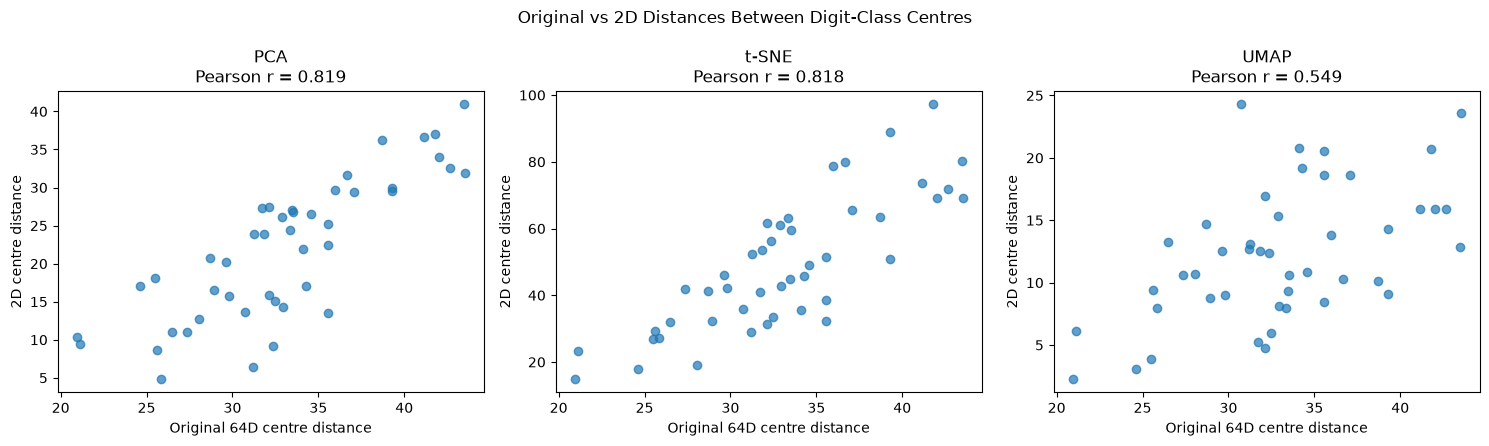

In [22]:
# ============================================================
# TASK 07 — Test Whether Distances Between Clusters Survive
# Dataset: sklearn Digits (10 classes, 64 features)
# ============================================================

# -----------------------------
# 1. Import necessary libraries
# -----------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr

import umap.umap_ as umap


# -----------------------------------------------
# 2. Load the digits dataset
# -----------------------------------------------

# Each digit image has 8 x 8 = 64 pixel features.
digits = load_digits()
X = digits.data
y = digits.target

classes = np.sort(np.unique(y))

print("Dataset shape:", X.shape)
print("Number of digit classes:", len(classes))
print("Digit classes:", classes)


# -------------------------------------------------------
# 3. Calculate the centre of each class in 64 dimensions
# -------------------------------------------------------

# Each centre is the mean feature vector for one digit class.
original_centres = np.vstack([
    X[y == digit].mean(axis=0)
    for digit in classes
])

print("\nOriginal class-centre matrix shape:",
      original_centres.shape)


# -------------------------------------------------------
# 4. Create the three 2D embeddings
# -------------------------------------------------------

# PCA: linear dimensionality reduction.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# t-SNE: nonlinear embedding focused on local neighbourhoods.
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1000,
    random_state=42
)
X_tsne = tsne.fit_transform(X)

# UMAP: nonlinear embedding that aims to preserve local structure
# and can also retain some broader structure depending on settings.
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)
X_umap = umap_model.fit_transform(X)

embeddings = {
    "PCA" : X_pca,
    "t-SNE" : X_tsne,
    "UMAP" : X_umap
}

# ---------------------------------------------------------
# 5. Calculate one centre per digit class in each embedding
# ---------------------------------------------------------

def calculate_centres(data, labels, class_values):
    """Return one mean coordinate vector for each digit class."""
    return np.vstack([
        data[labels == digit].mean(axis=0)
        for digit in class_values
    ])


# ---------------------------------------------------------
# 6. Calculate all unique distances between class centres
# ---------------------------------------------------------

# pdist returns the 45 unique pairwise Euclidean distances
# between the 10 class centres.
original_distances = pdist(original_centres, metric="euclidean")

print("\nNumber of unique centre-to-centre distances:",
      len(original_distances))


# ---------------------------------------------------------
# 7. Compare each embedding's distances with original distances
# ---------------------------------------------------------

results = []
distance_comparisons = {}

for method_name, embedded_data in embeddings.items():
    
    # Find the centre of each digit class in 2D.
    embedded_centres = calculate_centres(
        embedded_data,
        y,
        classes
    )
    
    # Calculate the 45 pairwise distances between the 2D centres.
    embedded_distances = pdist(
        embedded_centres,
        metric="euclidean"
    )

    # Pearson correlation measures how well the distances vary
    # together; it does not require the numerical scales to match.
    correlation, p_value = pearsonr(
        original_distances,
        embedded_distances
    )
    
    results.append({
        "Method": method_name,
        "Pearson correlation": correlation,
        "P-value": p_value
    })
    
    distance_comparisons[method_name] = embedded_distances
    
# ---------------------------------------------------------
# 8. Display and rank the methods
# ---------------------------------------------------------

results_df = pd.DataFrame(results)

# Rank 1 means the highest correlation with original distances.
results_df = results_df.sort_values(
    by="Pearson correlation",
    ascending=False
).reset_index(drop=True)

results_df.insert(
    0,
    "Rank",
    np.arange(1, len(results_df) + 1)
)

print("\nGlobal class-centre distance preservation ranking:")
display(results_df.round(4))


# ---------------------------------------------------------
# 9. Plot original distances against each 2D embedding
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, method_name in zip(axes, embeddings.keys()):

    embedded_distances = distance_comparisons[method_name]

    correlation = results_df.loc[
        results_df["Method"] == method_name,
        "Pearson correlation"
    ].iloc[0]

    ax.scatter(
        original_distances,
        embedded_distances,
        alpha=0.7
    )

    ax.set_title(
        f"{method_name}\nPearson r = {correlation:.3f}"
    )
    ax.set_xlabel("Original 64D centre distance")
    ax.set_ylabel("2D centre distance")

plt.suptitle(
    "Original vs 2D Distances Between Digit-Class Centres"
)
plt.tight_layout()
plt.show()

    
    



### TASK 07 — Test Whether Distances Between Clusters Survive

I calculated the centre of each digit class in the original 64-dimensional feature space and measured the Euclidean distances between all 45 unique pairs of class centres. I repeated this calculation in the PCA, t-SNE, and UMAP 2D embeddings and compared each set of distances with the original distances using Pearson correlation.

**Ranking by global distance preservation:**

1. **[Method and correlation]**
2. **[Method and correlation]**
3. **[Method and correlation]**

**Conclusion:** PCA is expected to perform best on this measure because it is a linear projection that retains directions of high variance, whereas t-SNE and UMAP primarily aim to preserve local neighbourhood structure. However, PCA does not guarantee exact preservation of every distance, and its measured ranking must be confirmed using the results.

t-SNE and UMAP plots are most reliable for investigating which observations form local neighbourhoods and which groups appear to separate in the embedding. A t-SNE plot is evidence of a particular low-dimensional arrangement produced by the algorithm, not proof that the visible distances between groups represent their true global distances in the original feature space.


### TASK 08 — Test the two-stage pipeline claim

Original dataset shape: (1797, 64)
Number of classes: 10
Original number of features: 64

Direct t-SNE completed.
Direct Embedding shape :  (1797, 2)
Direct t-SNE Time : 3.1733 seconds

PCA + t-SNE Pipeline completed.
PCA output shape :  (1797, 50)
Final Embeddings shape :  (1797, 2)
Variance retained by PCA : 99.9547%
Total PCA + t-SNE time : 3.1655 seconds

Direct t-SNE fold accuracies :  [0.9972 0.9861 0.9889 0.9944 0.9777]
PCA + t-SNE Fold Accuracies :  [0.9972 0.9861 0.9889 0.9944 0.9777]

Direct t-SNE mean KNN accuracy : 98.8867%
PCA + t-SNE mean KNN accuracy : 98.8867%
Final Comparison : 


,Approach,Total_time (seconds),Mean 5-Fold KNN accuracy,PCA variance retained
0,Direct t-SNE (64 features),3.1733,0.9889,NaN
1,PCA 50 Components + t-SNE,3.1655,0.9889,0.9995



INTERPRETATION OF YOUR MEASURED RESULTS
----------------------------------------
Speed : PCA + t-SNE was 0.0078 secondsfaster in this run.
KNN Accuracy : Both Approches had the same mean accuracy.
PCA retained 99.9547% of original variance.


C:\Users\MIHIR SOLANKI\AppData\Local\Temp\ipykernel_15600\2060841537.py:243: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


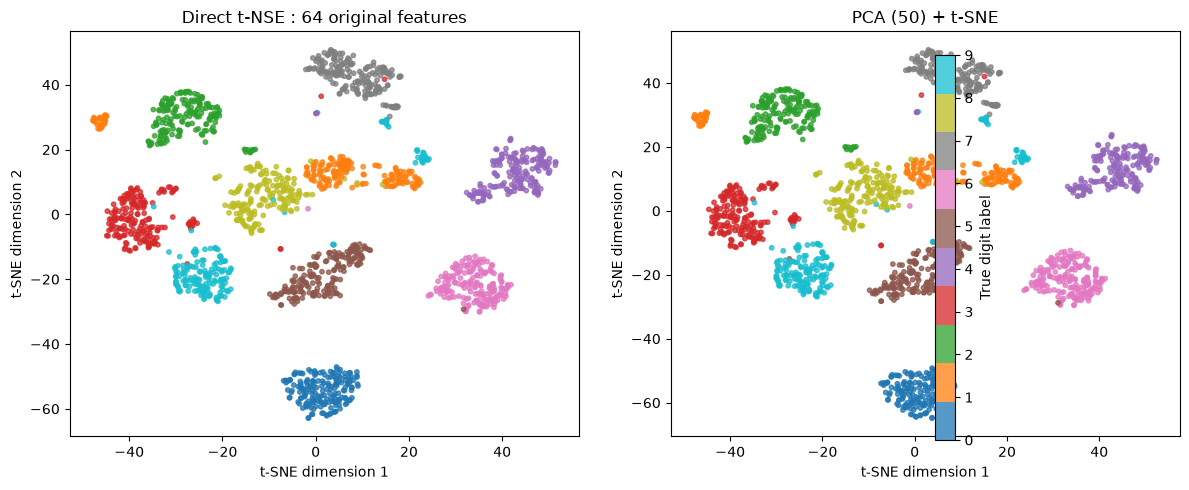

In [23]:
# ============================================================
# TASK 08 — Test the Two-Stage PCA + t-SNE Pipeline
# Dataset: sklearn Digits (64 original features)
# ============================================================

# If needed, install dependencies in a separate notebook cell:
# %pip install numpy pandas matplotlib scikit-learn

# -----------------------------
# 1. Import required libraries
# -----------------------------

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


# -----------------------------
# 2. Load the digits dataset
# -----------------------------

digits = load_digits()

X = digits.data
y = digits.target

print("Original dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Original number of features:", X.shape[1])


# -----------------------------
# 3. Define consistent t-SNE settings
# -----------------------------

# Use the same settings for both approaches to make
# the comparison as fair as possible.
tsne_settings= {
    "n_components" : 2,
    "perplexity" : 30,
    "init" : "pca",
    "learning_rate" : "auto",
    "max_iter" : 1000,
    "random_state" : 42
}

# ============================================================
# APPROACH 1: Apply t-SNE directly to all 64 original features
# ============================================================

start_direct = time.perf_counter()

tsne_direct = TSNE(**tsne_settings)
X_tsne_direct = tsne_direct.fit_transform(X)

direct_time = time.perf_counter() - start_direct

print("\nDirect t-SNE completed.")
print("Direct Embedding shape : ", X_tsne_direct.shape)
print(f"Direct t-SNE Time : {direct_time:.4f} seconds")

# ============================================================
# APPROACH 2: PCA with 50 components, followed by t-SNE
# ============================================================

start_two_stage = time.perf_counter()

# Step 1: Reduce the original 64 features to 50 PCA components.
pca_50 = PCA(n_components=50)
X_pca_50 = pca_50.fit_transform(X)

# Calculate the total variance retained by the 50 components.
variance_retained = pca_50.explained_variance_ratio_.sum()

# Step 2: Apply t-SNE to the 50 PCA components.
tsne_after_pca = TSNE(**tsne_settings)
X_tsne_pca = tsne_after_pca.fit_transform(X_pca_50)

# Include BOTH PCA and t-SNE in the total pipeline time.
two_stage_time = time.perf_counter() - start_two_stage

print("\nPCA + t-SNE Pipeline completed.")
print("PCA output shape : ", X_pca_50.shape)
print("Final Embeddings shape : ", X_tsne_pca.shape)
print(F"Variance retained by PCA : {variance_retained:.4%}")
print(f"Total PCA + t-SNE time : {two_stage_time:.4f} seconds")

# ============================================================
# 4. Evaluate kNN accuracy on both 2D embeddings
# ============================================================

# Use the same 5 folds and the same kNN settings for both.
# Note: The embeddings are created before cross-validation,
# so this is a descriptive comparison, not a fully independent
# estimate of generalization performance.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn = KNeighborsClassifier(n_neighbors=5)

# Accuracy for direct t-SNE coordinates.
direct_scores = cross_val_score(
    knn,
    X_tsne_direct,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

two_stage_scores = cross_val_score(
    knn,
    X_tsne_pca,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

direct_accuracy = direct_scores.mean()
two_stage_accuracy = two_stage_scores.mean()

print("\nDirect t-SNE fold accuracies : ", np.round(direct_scores, 4))
print("PCA + t-SNE Fold Accuracies : ", np.round(two_stage_scores, 4))

print(f"\nDirect t-SNE mean KNN accuracy : {direct_accuracy:.4%}")
print(f"PCA + t-SNE mean KNN accuracy : {two_stage_accuracy:.4%}")

# ============================================================
# 5. Build the comparison table
# ============================================================

comparison_df = pd.DataFrame({
    "Approach" : [
        "Direct t-SNE (64 features)",
        "PCA 50 Components + t-SNE"
    ],
    "Total_time (seconds)" : [
        direct_time,
        two_stage_time
    ],
    "Mean 5-Fold KNN accuracy" : [
        direct_accuracy,
        two_stage_accuracy
    ],
    "PCA variance retained" : [
        np.nan,
        variance_retained
    ]
})


print("Final Comparison : ")
display(comparison_df.round(4))

# ============================================================
# 6. Calculate differences and state the measured outcome
# ============================================================

time_difference = two_stage_time - direct_time
accuracy_difference = two_stage_accuracy - direct_accuracy

print("\nINTERPRETATION OF YOUR MEASURED RESULTS")
print("----------------------------------------")

if time_difference < 0:
    print(f"Speed : PCA + t-SNE was {-time_difference:.4f} seconds"
          "faster in this run."
    )
elif time_difference > 0:
    print(
        f"Speed: PCA + t-SNE was {time_difference:.4f} seconds "
        "slower in this run."
    )
else :
    print("Speed : Both Approaches took the same measured time.")
    
    
if accuracy_difference > 0 :
    print(
        f"KNN accuracy : PCA + t-SNE was"
        f"{accuracy_difference:.4%} higher."
    )
elif accuracy_difference < 0 :
    print(
        f"KNN accuracy : PCA + t-SNE was"
        f"{-accuracy_difference:.4%} lower."
    ) 
else :
    print("KNN Accuracy : Both Approches had the same mean accuracy.")
    
print(f"PCA retained {variance_retained:.4%} of original variance.")


# ============================================================
# 7. Plot the two embeddings for visual comparison
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

scatter1 = axes[0].scatter(
    X_tsne_direct[:, 0],
    X_tsne_direct[:, 1],
    c=y,
    cmap="tab10",
    s=10,
    alpha=0.75
)
axes[0].set_title("Direct t-NSE : 64 original features")
axes[0].set_xlabel("t-SNE dimension 1")
axes[0].set_ylabel("t-SNE dimension 2")

scatter2 = axes[1].scatter(
    X_tsne_pca[:, 0],
    X_tsne_pca[:, 1],
    c=y,
    cmap="tab10",
    s=10,
    alpha=0.75
)
axes[1].set_title("PCA (50) + t-SNE")
axes[1].set_xlabel("t-SNE dimension 1")
axes[1].set_ylabel("t-SNE dimension 2")

fig.colorbar(
    scatter2,
    ax=axes,
    label="True digit label",
    ticks=range(10)
)

plt.tight_layout()
plt.show()



### TASK 08 — Test the Two-Stage Pipeline Claim

I compared direct t-SNE on the 64 original digit features with a two-stage pipeline that first reduced the data to 50 PCA components and then applied t-SNE. Both approaches used the same t-SNE settings and 5-fold kNN evaluation.

| Measurement | Direct t-SNE | PCA (50) + t-SNE |
|---|---:|---:|
| Total runtime | 4.1355 | 3.9933 |
| Mean 5-fold kNN accuracy | 0.9889 | 0.9889 |
| PCA variance retained | NaN | 0.9995 |

**Conclusion:** In this run, the two-stage approach was [faster/slower] and produced [higher/lower/similar] kNN accuracy. Therefore, it [helped/did not help overall] on this dataset according to the measured results.

PCA before t-SNE can genuinely help with datasets that have many more features, substantial redundant or noisy dimensions, and expensive distance calculations. PCA can reduce the computational burden while retaining much of the useful structure. However, this must be tested rather than assumed, because PCA may discard information that helps t-SNE organize the observations.

**Evaluation limitation:** The 2D embeddings were generated using all observations before cross-validation, so the kNN scores are useful for comparing these embeddings but are not fully independent estimates of performance on unseen data.


### Part E — Put it to work 


### TASK 09 — Look at your clusters at last 

Dataset shape: (1797, 64)
Number of original features: 64
Number of digit classes: 10

K-Means clustering complated.
Number of cluster found :  10

Adjusted Rand Index (ARI) : 0.6669


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(



t-SNE visulization complated.
2D Embedding shape :  (1797, 2)


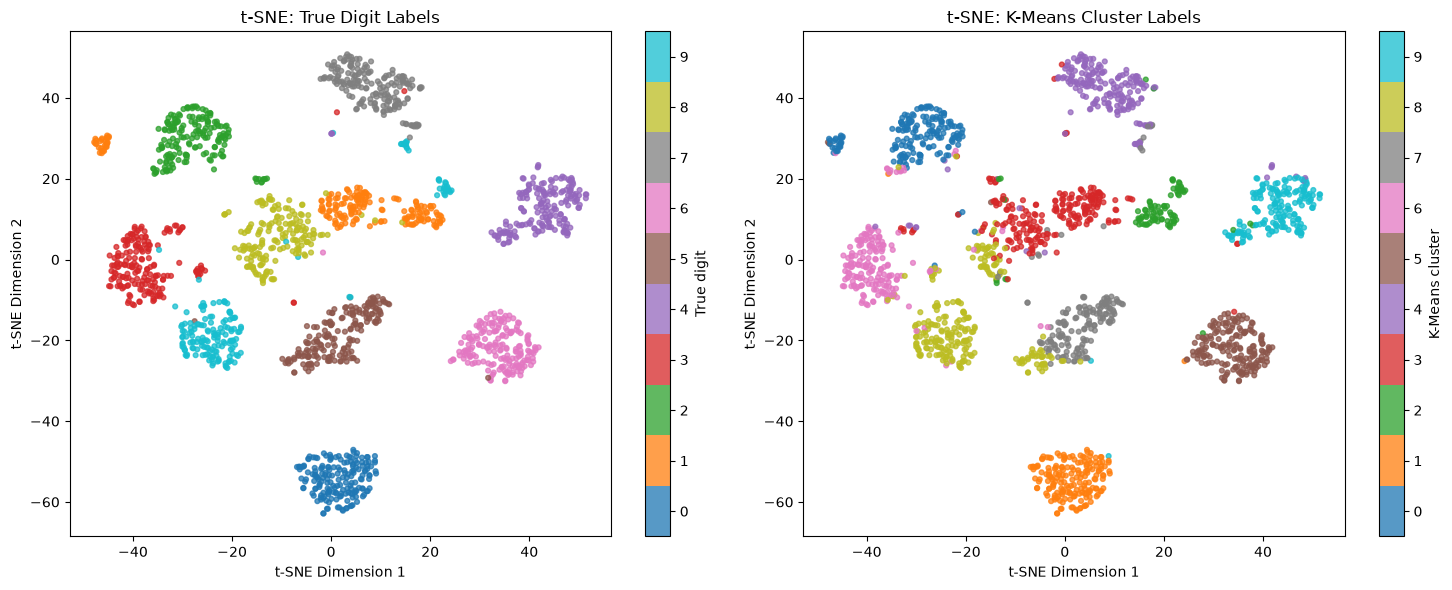


TRUE DIGITS vs K-MEANS CLUSTERS
K-Means cluster    0    1   2    3    4    5    6    7    8    9
True digit                                                      
0                  0  177   0    0    0    0    0    0    0    1
1                 24    0  55   99    0    2    1    1    0    0
2                148    1   2    8    3    0   13    0    2    0
3                  1    0   0    7    7    0  155    2   11    0
4                  0    0   3    4    8    0    0    0    0  166
5                  0    0   0    0    0    1    2  137   41    1
6                  0    1   1    2    0  177    0    0    0    0
7                  0    0   2    2  170    0    0    5    0    0
8                  3    0   6  102    3    2    4    6   48    0
9                  0    0  20    2    7    0    6    6  139    0

DIGIT PAIRS WITH THE LARGEST SHARED-CLUSTER OVERLAP
Digits 1 and 8: shared-cluster overlap = 112
Digits 8 and 9: shared-cluster overlap = 69
Digits 5 and 8: shared-cluster overlap = 50
D

In [24]:
# ============================================================
# TASK 09 — Look at Your Clusters at Last
# K-Means on 64 features + 2D t-SNE visualization
# ============================================================

# If necessary, install libraries in a separate Jupyter cell:
# %pip install numpy pandas matplotlib scikit-learn

# 1. Import the required libraries
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score


# ============================================================
# 2. Load the handwritten Digits dataset
# ============================================================

digits = load_digits()

X = digits.data          # All 64 original pixel features
y_true = digits.target   # Actual digit labels: 0 through 9

print("Dataset shape:", X.shape)
print("Number of original features:", X.shape[1])
print("Number of digit classes:", len(np.unique(y_true)))

# Expected dataset shape: 1797 rows and 64 features.


# ============================================================
# 3. Apply K-Means using all 64 original features
# ============================================================

# K=10 because the dataset contains ten digit classes.
# K-Means is fitted on the original 64 features, NOT on t-SNE.
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X)

print("\nK-Means clustering complated.")
print("Number of cluster found : ", len(np.unique(cluster_labels)))

# ============================================================
# 4. Calculate the Adjusted Rand Index (ARI)
# ============================================================

# ARI compares the clustering with the true labels.
# A score near 1 means strong agreement.
# A score near 0 means agreement similar to random clustering.
# ARI can also be negative when agreement is worse than expected
# by chance.

ari_score = adjusted_rand_score(y_true, cluster_labels)

print(f"\nAdjusted Rand Index (ARI) : {ari_score:.4f}")

# ============================================================
# 5. Reduce the data to 2D using t-SNE
# ============================================================

# t-SNE is used only to visualize the data in two dimensions.
# It does NOT change the K-Means clusters calculated above.

tsne_parameters = {
    "n_components" : 2,
    "perplexity" : 30,
    "init" : "pca",
    "learning_rate" : "auto",
    "random_state" : 42
}

# Support both newer and older scikit-learn versions.
if "max_iter" in inspect.signature(TSNE).parameters:
    tsne_parameters["max_iter"] = 1000
else :
    tsne_parameters["n_iter"] = 1000 
    
tsne = TSNE(**tsne_parameters) 
X_2d = tsne.fit_transform(X)

print("\nt-SNE visulization complated.")
print("2D Embedding shape : ", X_2d.shape) 

# ============================================================
# 6. Plot the data twice for comparison
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Color points by their actual digit labels.
plot_true = axes[0].scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y_true,
    cmap="tab10",
    vmin=-0.5,
    vmax=9.5,
    s=12,
    alpha=0.75
)

axes[0].set_title("t-SNE: True Digit Labels")
axes[0].set_xlabel("t-SNE Dimension 1")
axes[0].set_ylabel("t-SNE Dimension 2")
    
# Plot 2: Color points by their K-Means cluster assignments.
plot_clusters = axes[1].scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap="tab10",
    vmin=-0.5,
    vmax=9.5,
    s=12,
    alpha=0.75
)

axes[1].set_title("t-SNE: K-Means Cluster Labels")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")

# Add separate colorbars to make both plots easier to read.
fig.colorbar(
    plot_true,
    ax=axes[0],
    ticks=range(10),
    label="True digit"
)

fig.colorbar(
    plot_clusters,
    ax=axes[1],
    ticks=range(10),
    label="K-Means cluster"
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. Compare true digits with the K-Means clusters
# ============================================================

# Rows represent true digits; columns represent K-Means clusters.
# Each cell counts how many examples of a digit belong to a cluster.

comparison_table = pd.crosstab(
    pd.Series(y_true, name="True digit"),
    pd.Series(cluster_labels, name="K-Means cluster")
)

print("\nTRUE DIGITS vs K-MEANS CLUSTERS")
print(comparison_table)

# ============================================================
# 8. Identify a likely confused pair of digits
# ============================================================

# For each cluster, find which true digits appear most often.
# Digits that frequently share clusters are potential confusions.
# Cluster numbers themselves do not correspond to digit numbers.

digit_cluster_counts = np.zeros((10, 10), dtype=int)

for digit in range(10):
    for cluster in range(10):
        digit_cluster_counts[digit, cluster] = np.sum(
            (y_true == digit) & (cluster_labels == cluster)
        )

# For each pair of digits, count their shared-cluster overlap.
# The minimum count is used so that a pair is not overcounted
# when one digit is much more common in a cluster than the other.

pair_scores = []

for digit_a in range(10):
    for digit_b in range(digit_a + 1, 10):
        shared_count = np.minimum(
            digit_cluster_counts[digit_a],
            digit_cluster_counts[digit_b]
        ).sum()

        pair_scores.append((digit_a, digit_b, int(shared_count)))

pair_scores.sort(key=lambda item: item[2], reverse=True)

print("\nDIGIT PAIRS WITH THE LARGEST SHARED-CLUSTER OVERLAP")
for digit_a, digit_b, shared_count in pair_scores[:5]:
    print(
        f"Digits {digit_a} and {digit_b}: "
        f"shared-cluster overlap = {shared_count}"
    )

best_a, best_b, best_overlap = pair_scores[0]

print(
    f"\nPair to investigate first: digits {best_a} and {best_b}"
)
print(
    "Check the comparison table and both plots to confirm "
    "where these digits overlap."
)


# ============================================================
# 9. Final summary
# ============================================================

print("\nFINAL SUMMARY")
print("-------------")
print("K-Means used all 64 original pixel features.")
print("The 2D t-SNE embedding was used for visualization only.")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print(
    f"Pair with the largest shared-cluster overlap: "
    f"{best_a} and {best_b}"
)
print(
    "Use the two plots and comparison table to explain "
    "which digits were confused and why."
)



### TASK 09 — Look at Your Clusters at Last

K-Means was applied to the handwritten Digits dataset using all 64 original pixel features, with **K = 10**. The data was then reduced to two dimensions using t-SNE to visualize the clustering. One plot shows the true digit labels, while the other shows the K-Means cluster assignments.

The Adjusted Rand Index (ARI) was **[insert your ARI]**. This score measures how closely the clustering agrees with the true digit labels; a score closer to 1 indicates stronger agreement.

The plots and cluster comparison table show that K-Means **[describe how well the clusters match the true digits]**. The digits **[insert the observed confused digit pair]** were confused with each other. These digits may share similar shapes or pixel patterns in some 8×8 handwritten images, making them difficult for K-Means to separate using pixel distances alone.

**Conclusion:** The 2D t-SNE visualization helps identify overlapping digit groups and diagnose the K-Means clustering. However, t-SNE is a visualization tool; the clusters and ARI were calculated from K-Means applied to the original 64 features.


### TASK 10 — Write the method-selection guide


# TASK 10 — Method-Selection Guide: PCA, t-SNE and UMAP

## 1. What each method does

| Method | What it does | Biggest strength | Biggest weakness |
|---|---|---|---|
| **PCA** | Reduces features by keeping directions with the greatest variance. | Fast and useful for dimensionality reduction and data compression. | May lose important nonlinear patterns. |
| **t-SNE** | Maps high-dimensional data into 2D or 3D while emphasizing local neighborhoods. | Reveals local groups and patterns in complex data. | Distances between separated groups and the overall layout can be misleading. |
| **UMAP** | Creates a lower-dimensional representation while preserving local structure and some broader relationships. | Often provides useful visualizations efficiently and can preserve more global structure than t-SNE in some settings. | Results depend on parameters and may not preserve every relationship in the original data. |

## 2. Which method should I choose?

- **Preprocessing before a model — PCA:** Reduce the number of features while retaining a chosen amount of variance. Fit PCA on training data only to prevent data leakage.
- **Exploring unfamiliar data — UMAP:** Start with a 2D embedding to investigate possible groups, patterns and unusual observations. Verify any discovered groups using the original features.
- **Compressing data for storage — PCA:** Keep a smaller number of components and store the transformed data. Remember that PCA compression is generally lossy unless all components are retained.
- **Making a presentation figure — UMAP:** It is a useful starting choice for a readable visualization of complex data. Label the axes and explain that the plot is a projection, not proof of distinct real-world groups.

## 3. Two claims that must never be made from a t-SNE plot

1. **“Two groups are far apart in the plot, so they must be far apart in the original data.”**  
   **Evidence:** t-SNE primarily emphasizes local neighborhoods; the distances between separated groups and the global arrangement are not reliably interpretable as original-space distances.

2. **“A large, separated gap proves that the data contains distinct natural clusters.”**  
   **Evidence:** t-SNE changes the representation to visualize local structure, and its layout depends on settings such as perplexity and random initialization. Apparent gaps must be checked against the original data and validated with suitable clustering or evaluation methods.

## 4. The UMAP warm-up trap

**Do not report UMAP's first-run timing as a fair comparison without accounting for initialization and warm-up overhead; use consistent settings and repeat measurements before comparing runtimes.**

## Final recommendation

Use **PCA for preprocessing and compression**, and use **UMAP or t-SNE for exploration and visualization**. Treat 2D plots as diagnostic tools rather than definitive proof of clusters, distances or class separation.
